# ⬜️ Explainable AI with SHAP
This assignment utilizes the SHAP library to create explanations of machine learning models.

Make sure to use https://shap.readthedocs.io/en/latest/ throughout the assignment for API reference and examples.

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences are enough; there is no length requirement.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook to Canvas. Deliver the notebook with its outputs saved; ideally, *restart* the kernel and then *run all*.


Good luck!

---

## 🏡 Problem 1: Explaining housing prediction models using SHAP
### ❗️ The problem
You will use SHAP values to create explanations of a linear model and a boosting model on the California housing dataset.

### 📋 Formal requirements
1. **Implementation**:
   - Compare feature importance by coefficients and by SHAP for the linear model
   - Explain the boosting model globally with SHAP plots
   - Compare two local explanations with waterfall plots
2. **Discussion**:
   - What is the baseline in the SHAP plots, and what are the background samples for?
   - The coefficient plot and SHAP disagree on which features are important. Why, and which do you prefer?
   - How does the beeswarm plot visualize SHAP values? Which features are most important?
   - Are there any features that do not have a monotonic relationship with SHAP values?
   - Which of **houseA** and **houseB** has the highest predicted value?
   - How did the boosting model arrive at the predictions for **houseA** and **houseB**?
   - If we made the model blind to **MedInc**, which house would have the highest value?


In [ ]:
# !pip install shap

### Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset


### Data preparation

I had some issues with the http request getting the california dataset, so I found it in a github repo but I had to do some stuff to it as you can see 

In [84]:
df = pd.read_csv("california_housing.csv").dropna()
data = pd.DataFrame({
    "MedInc": df["median_income"],
    "HouseAge": df["housing_median_age"],
    "AveRooms": df["total_rooms"] / df["households"],
    "AveBedrms": df["total_bedrooms"] / df["households"],
    "Population": df["population"],
    "AveOccup": df["population"] / df["households"],
    "Latitude": df["latitude"],
    "Longitude": df["longitude"],
})

target = df["median_house_value"]/100000



X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=0)

# We have 8 features and a single target value (the value of the house).
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
X_train.head()


X_train shape: (16346, 8)
y_train shape: (16346,)
X_test shape: (4087, 8)
y_test shape: (4087,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
15610,5.7652,13,6.497018,0.976143,1431,2.844930,32.72,-116.87
12478,1.6116,52,3.706250,1.065625,1038,3.243750,38.59,-121.48
5996,3.5313,36,5.092409,0.980198,1355,4.471947,34.09,-117.73
11827,3.9734,17,6.215584,1.037662,2066,2.683117,39.01,-121.02
5183,1.6500,41,3.881748,1.053985,1408,3.619537,33.94,-118.26


### The linear model


R2 Score: 0.606


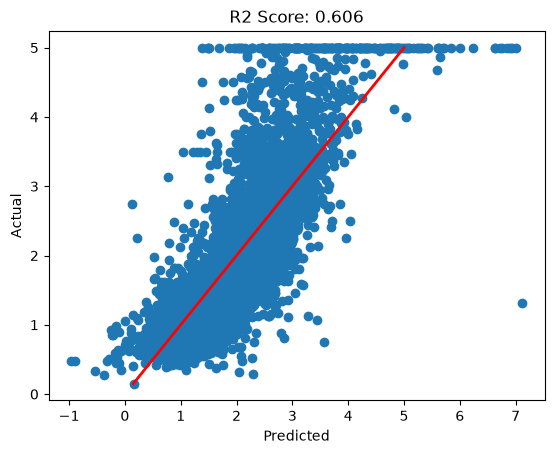

In [85]:
# Train a linear model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Plot predicted vs actual values
score = r2_score(y_test, linear_model.predict(X_test))
print(f"R2 Score: {score:.3f}")
plt.title(f"R2 Score: {score:.3f}")
plt.scatter(linear_model.predict(X_test), y_test)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Coefficients

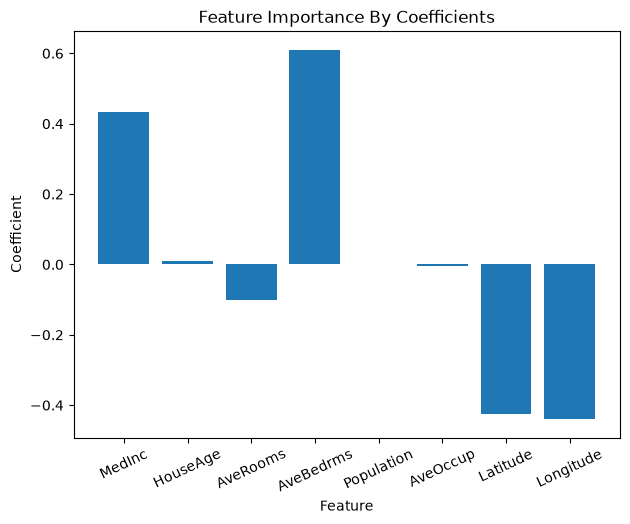

In [86]:
# Plot the coefficients of the linear model with feature names
# For linear models, the coefficients are a very common way to interpret feature importance. Seems reasonable, right?
plt.bar(data.columns, linear_model.coef_)
plt.xlabel("Feature")
plt.ylabel("Coefficient")
plt.tight_layout()
plt.title("Feature Importance By Coefficients")
plt.xticks(rotation=25)
plt.show()

### SHAP feature importance

SHAP values shape: (4087, 8)


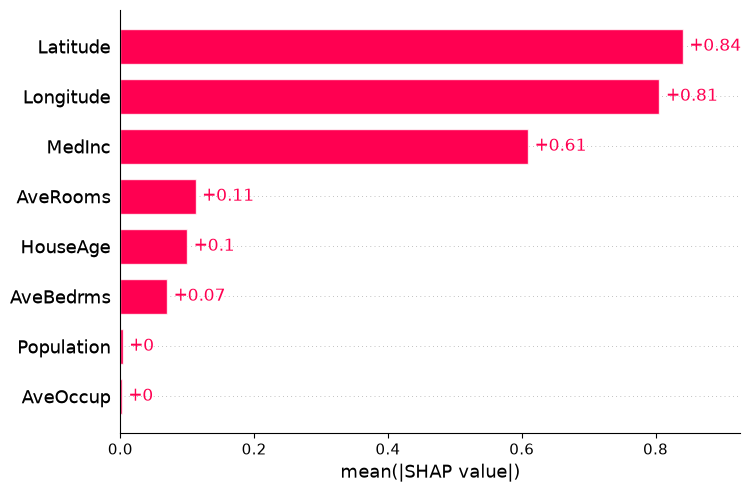

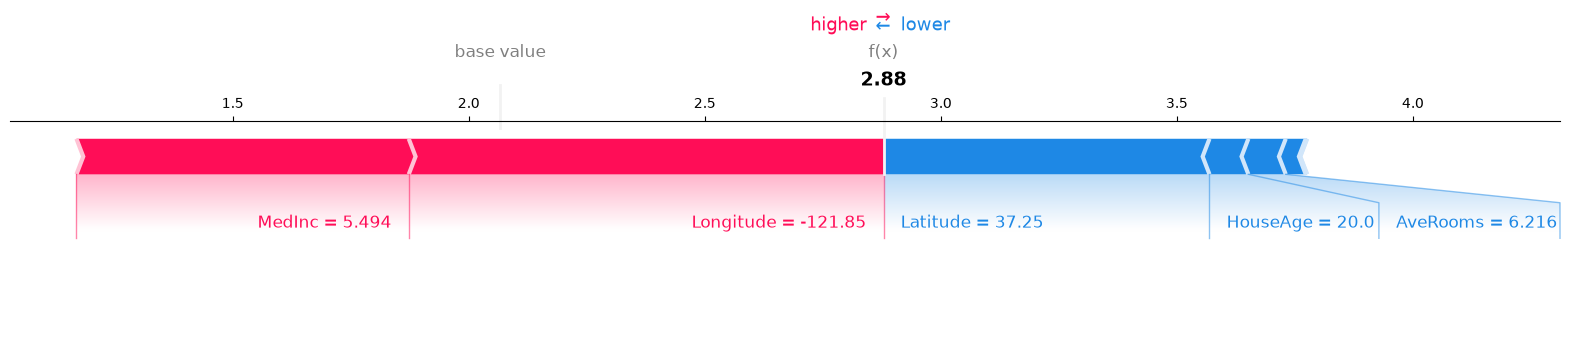

MedInc :  3.866319992658754
HouseAge :  28.664994494065827
AveRooms :  5.431447025395365
AveBedrms :  1.0972902237168978
Population :  1425.4893551939313
AveOccup :  3.106117903975948
Latitude :  35.625975773889635
Longitude :  -119.56280802642848


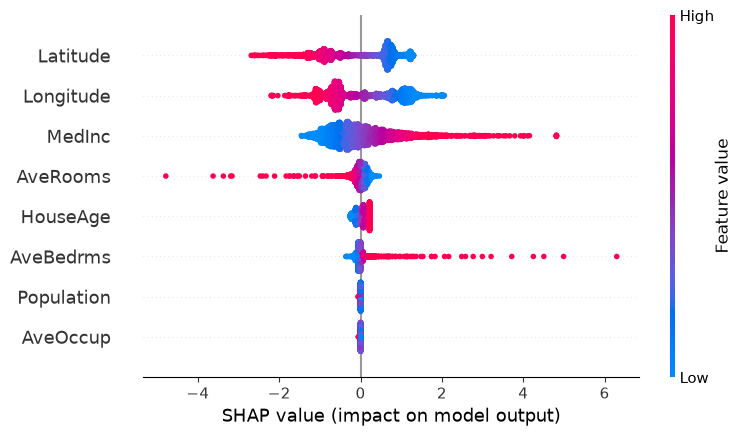

In [87]:
# We need to provide SHAP a background dataset for reference samples.
background = X_train # TODO
masker = shap.maskers.Independent(X_train, max_samples=len(X_train))
explainer = shap.Explainer(linear_model, masker)
features = data.columns

shap_values = explainer.shap_values(X_test) # TODO: Compute SHAP values for the test set
print(f"SHAP values shape: {shap_values.shape}")
# TODO: bar plot with averaged absolute SHAP values
sv = explainer(X_test)
shap.plots.bar(sv)
i = 6
X_test.iloc[i]
shap.force_plot(explainer.expected_value,shap_values[i,:],X_test.iloc[i].round(3),feature_names = features, matplotlib=True)
for _feature in features:
    print(_feature, ": ", X_train[_feature].mean())
shap.plots.beeswarm(explainer(X_test))


### ❓ What is the baseline in the SHAP plots, and what are the background samples for?
The baseline, or the expected value, is the average prediction over the background samples. In a SHAP plot its where every epxlanation starts, then SHAP explains why we *dont* have this value (like we see in the force plot). prediction = baseline + sum of SHAP values for all features. 

A model cannot simply remove a feature to see what it contributes. SHAP then needs a reference distribution to stand in for the "unkown" feature. The background samples are this. To measure the effect of a feeature, SHAP replaces the value with values drawn from the background sample distribution, and then sees how the prediction changes. So one could say the background does two things, it defines the baseline, and it defines what "missing" means for every feature, and thus determines the shap values themselves. 


In [88]:
print(f"{np.mean(target):.2f}")

2.07


### ❓ The coefficient plot and SHAP disagree on which features are important. Why, and which do you prefer? (hint: plot feature histograms)
the coefficient plot ranks average bedrooms as most imporant, and shap ranks longitude and latitude first and average bedrooms only sixth. The reason is that a coefficient only describes the effect of a one unit change in a feature, and it depends on the feature scale and units. For a linear model, the shap value is coef*(x-mean), so it also takes into account the variation of the feature in the data. 

The histogram below shows this quite clearly. Average bedrooms is concentrated in a very narrow range around 1, so even with a large coefficient it rarely changes the prediction much, and its mean value is small. House age has a small coefficient, but it spreads much more so it contributes more to the predictions. Longitude and latitude both has a large coefficient and is spread widely, thus becoming the most important according to shap. 

I think I prefer SHAP for judging feature importance as it puts all features on the same scale, and reflects their real impact on predicitions across the dataset. The coefficients are still useful for the per unit effect of a feature, but they should not be compared across features that are on different scales. Coefficients can also be unreliable when features are correlated. 


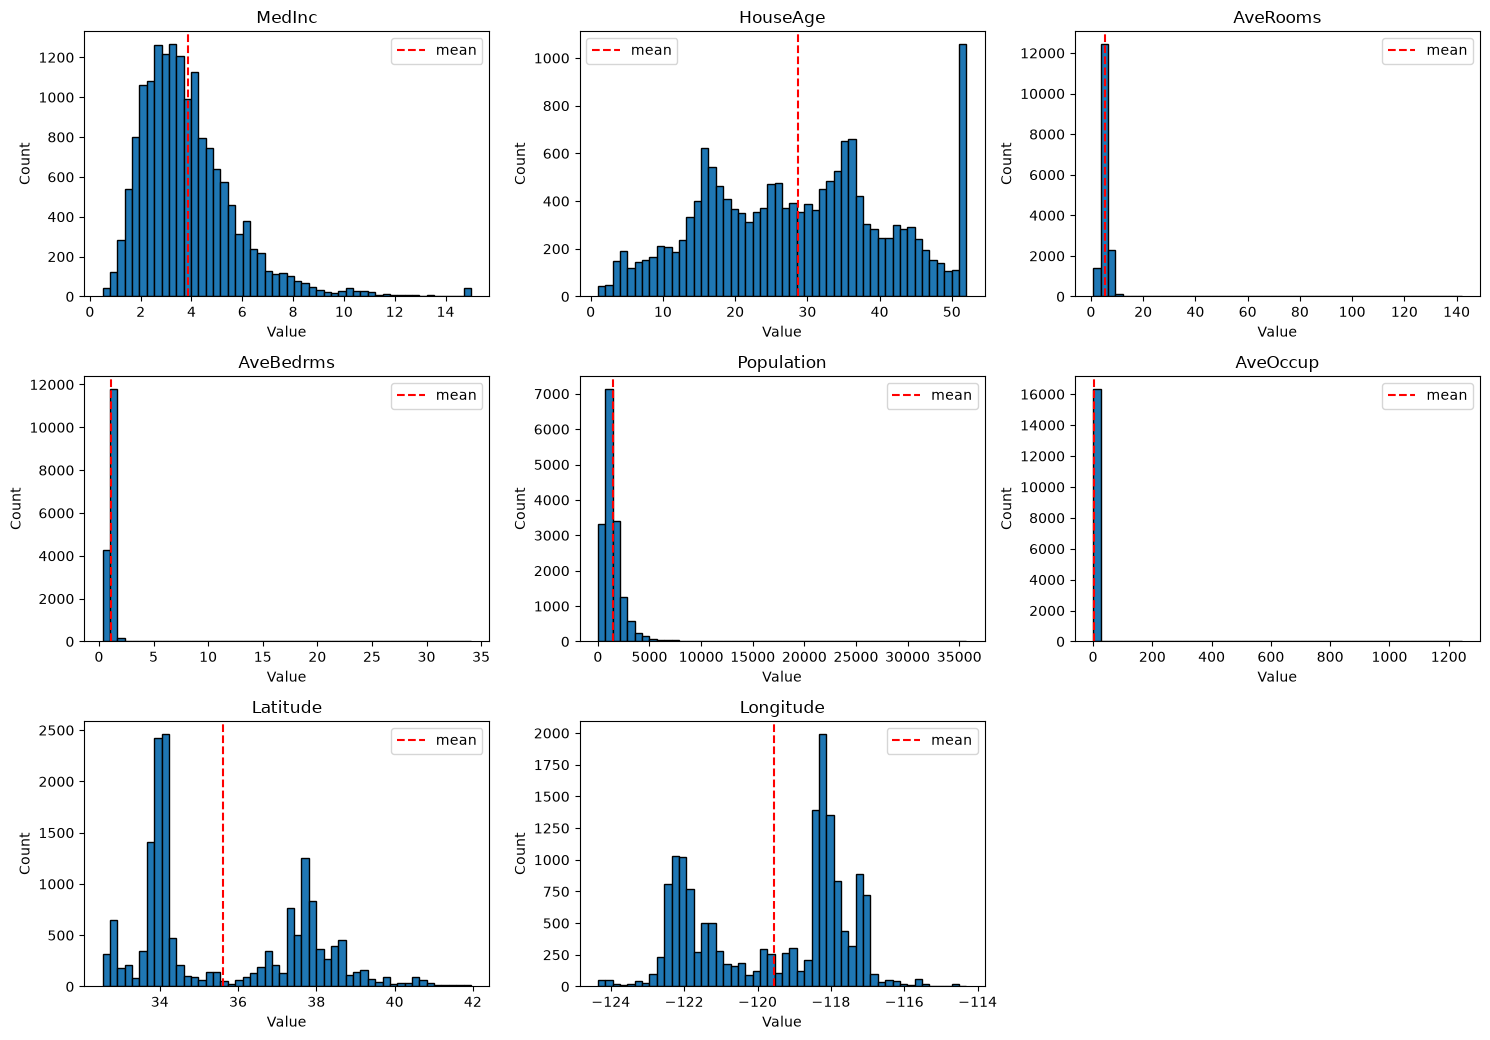

In [89]:
import math

features = X_train.columns
n_cols = 3
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    ax.hist(X_train[feature], bins=50, edgecolor="black")
    ax.axvline(X_train[feature].mean(), color="red", linestyle="--", label="mean")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
    ax.legend()

# Hide any unused subplots
for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### The boosting model

R^2 score: 0.823


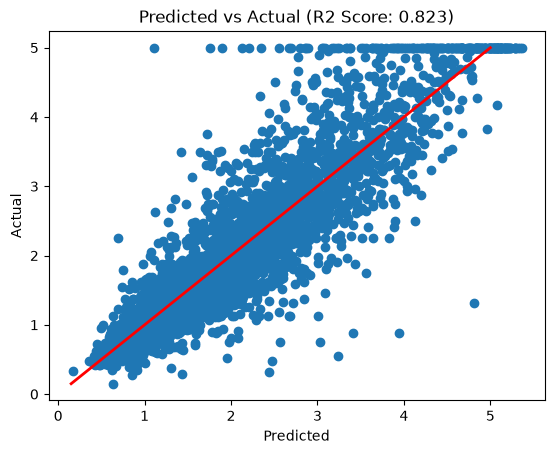

In [99]:
# Train a boosting model
boosting_model = GradientBoostingRegressor(max_depth=5, random_state=0)
boosting_model.fit(X_train, y_train)

# Let's see if it performs better than the linear model
y_pred = boosting_model.predict(X_test)
score = r2_score(y_test, y_pred)
print(f"R^2 score: {score:.3f}")
plt.scatter(y_pred, y_test)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Predicted vs Actual (R2 Score: {score:.3f})")
plt.show()

In [92]:
print(X_train.shape)
print(X_test.shape)

(16346, 8)
(4087, 8)


Background dataset has 1000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1000 when initializing the masker.


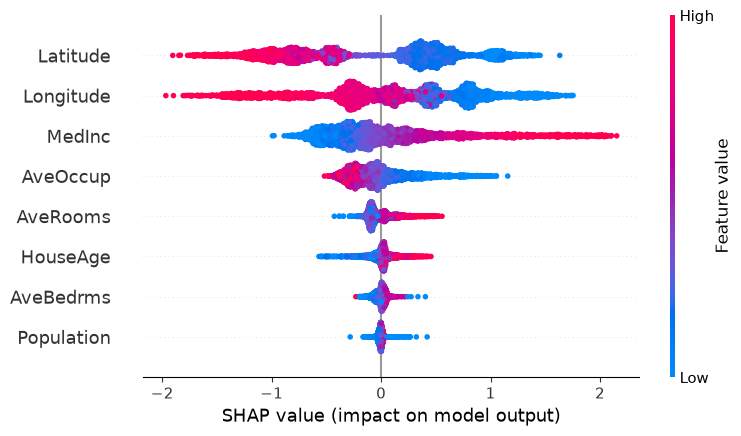

In [100]:
explainer = shap.TreeExplainer(boosting_model, data=shap.sample(X_train, 1000))
shap_values = explainer(X_test, check_additivity=False)
shap.plots.beeswarm(shap_values)

### ❓ How does the beeswarm plot visualize SHAP values? Which features are most important?
On the y axis you have the features, ranked on importance (here latitude is seen as most important). The X axis shows the shap value for the feature. The dots are also given a color, which indicates the value of the feature being high or low. For example if we look at the median income, we see that high median income has a high shap value. That means that high income tends to contribute positively to the house price, and vice versa.

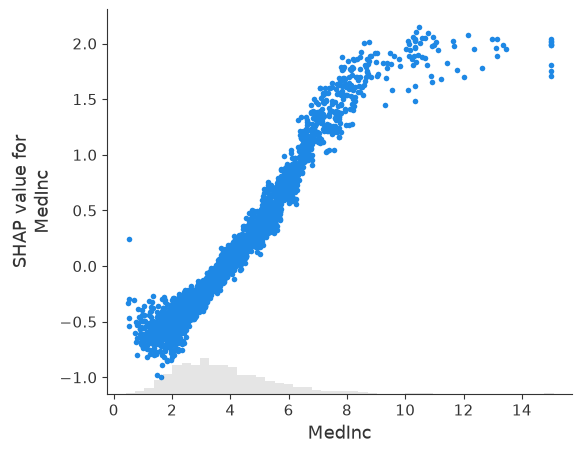

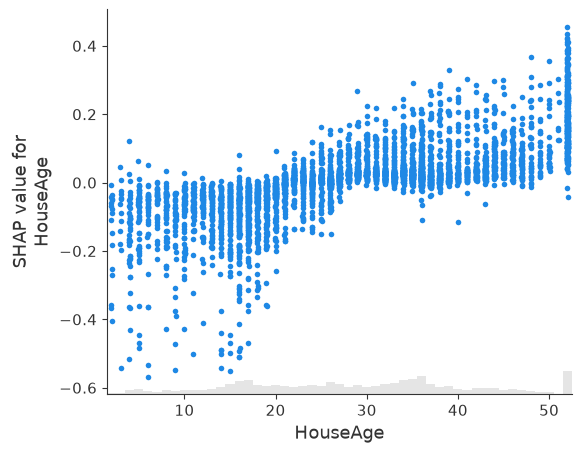

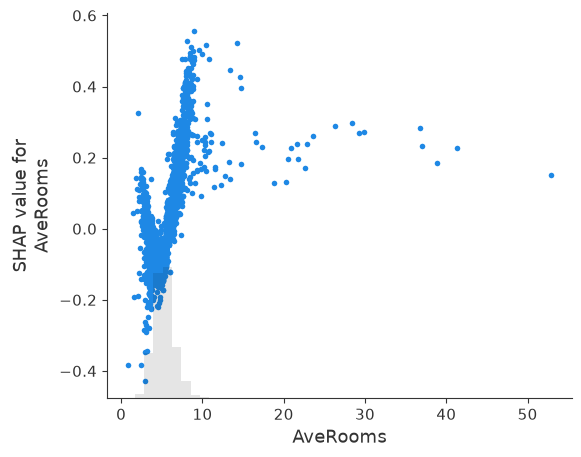

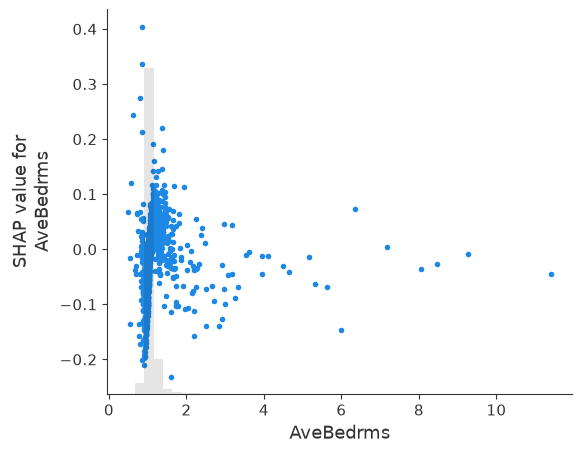

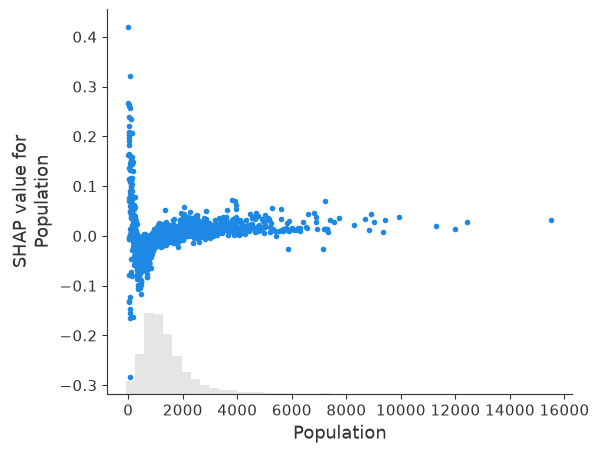

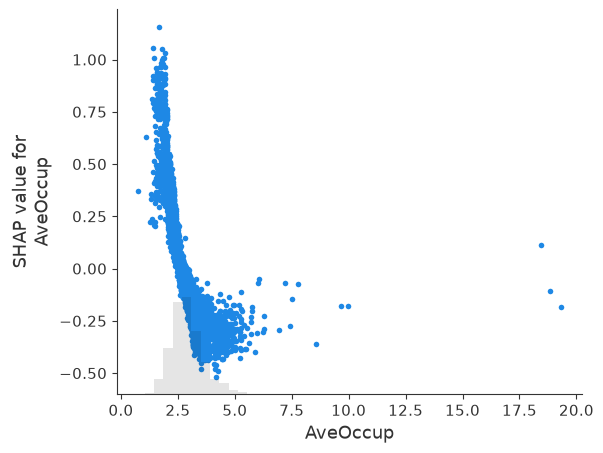

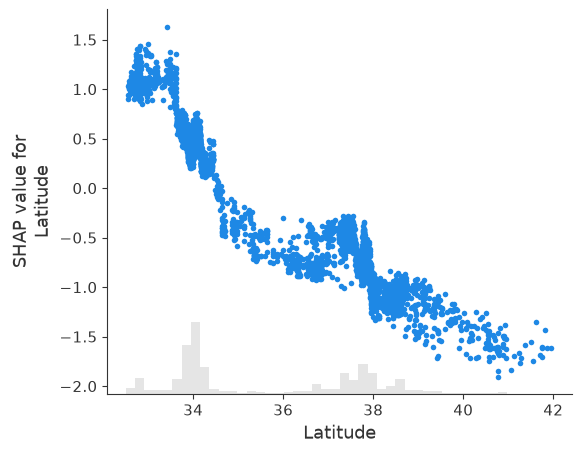

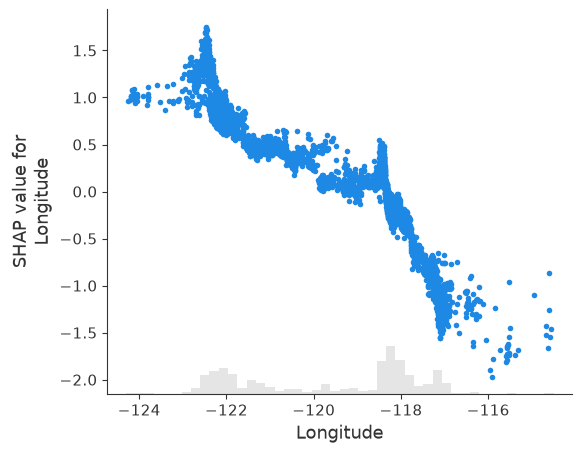

In [101]:
# All features in a loop
for f in X_test.columns:
    shap.plots.scatter(shap_values[:, f])

### ❓ Are there any features that do not have a monotonic relationship with SHAP values? (hint: try shap.plots.scatter)
It would appear that average rooms has a non monotonic relationship with SHAP values. Look at the scatterplot. It starts out decreasing a lot, before increasing sharply, then flattening. 

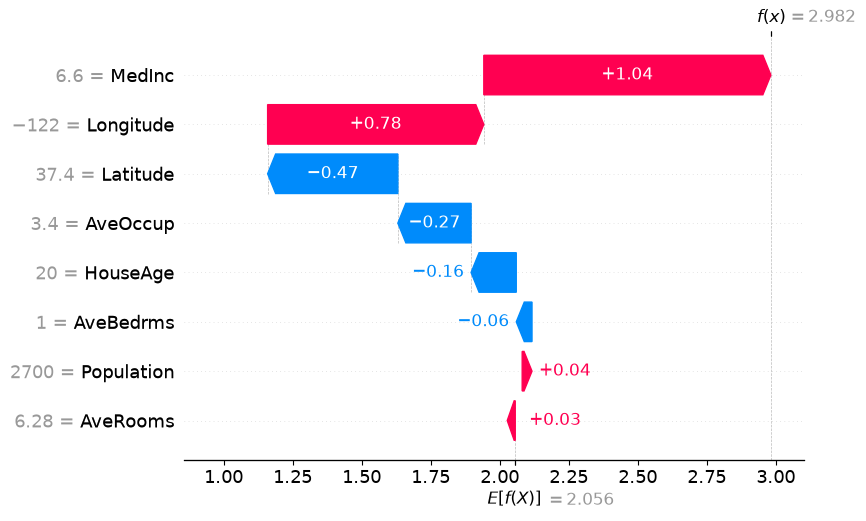

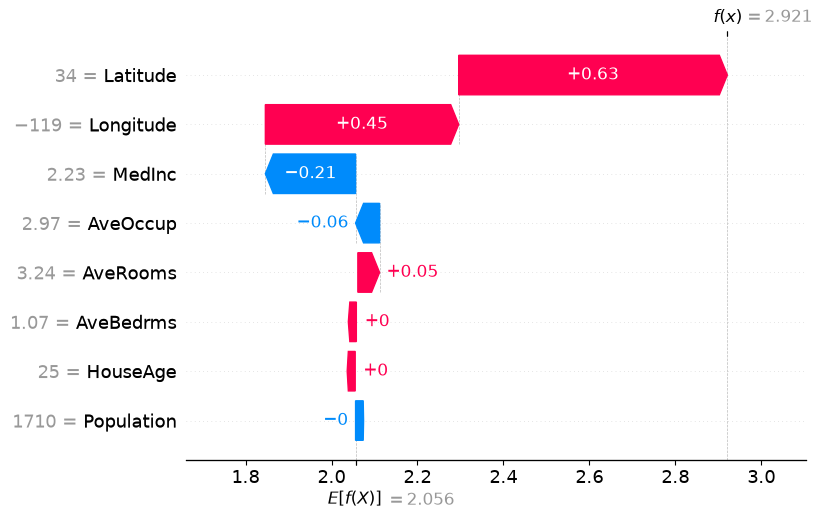

In [102]:

houseA = pd.DataFrame([[6.6, 20, 6.28, 1.0, 2700, 3.4, 37.4, -122]], columns=X_test.columns)
houseB = pd.DataFrame([[2.23, 25, 3.24, 1.07, 1710, 2.97, 34, -119]], columns=X_test.columns)

shap_A = explainer(houseA)
shap_B = explainer(houseB)

shap.plots.waterfall(shap_A[0])
shap.plots.waterfall(shap_B[0])

### ❓ Which of houseA and houseB has the highest predicted value?
House A has the highest predicted value. 

### ❓ How did the boosting model arrive at the predictions for houseA and houseB?
The models prediction for each house is the baseline plus the shap values for each feature, like we see in the waterfall plots. To arrive at the prediciton for each house, it takes the E(f(x))=2.056 and sums up the SHAP values for each feature. Then House A came out on top. 

### ❓ If we made the model blind to MedInc, which house would have the highest value?
Then house A would get 1.942, and house B would get 3,131, so house B would be higher values. This comes down to the longitude and latitude, so I guess the area drives the price up. Seems legit. (to arrive at this I just subtracted the median income shap value from each prediction, whcihc is an approximation for what the model would give. Training the model without the feature would probably not give the precise same answer.)

## 🔢 Problem 2: Explaining an MNIST neural network


### ❗️ The problem
Explain a neural network trained on the MNIST dataset. Use SHAP to explain which pixels are important for detecting particular digits.

### 📋 Formal requirements
1. **Implementation**:
   - Explain predictions with `shap.DeepExplainer`
   - Find the class probabilities of `encrypted_image`
2. **Discussion**:
   - What does each row, column and pixel in the SHAP image plot represent?
   - How does the model generally predict the digit 0?
   - Which digit has the largest probability for `encrypted_image`? Why is the model so confident, can we trust it?
   - Why is DeepExplainer not a model agnostic explanation method?

### Fetch MNIST

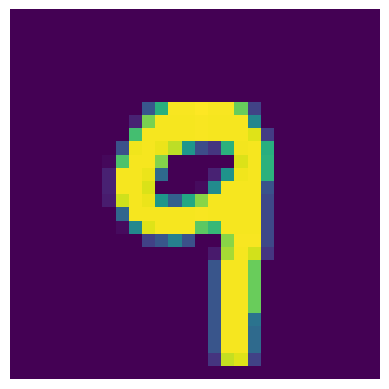

In [3]:
# Download MNIST dataset
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Images are originally 1d: reshape back to 28x28.
plt.imshow(X_train[1337].reshape(28, 28))
plt.axis("off")
plt.show()

### Prepare data and hyperparameters

In [4]:
# Hyperparameters
learning_rate = 0.0005
epochs = 10
batch_size = 64
loss_fn = torch.nn.CrossEntropyLoss()

# Scale and convert to tensors
X_train = torch.tensor(X_train / 255.0, dtype=torch.float32)
X_test = torch.tensor(X_test / 255.0, dtype=torch.float32)
y_train = torch.tensor(y_train.astype(int), dtype=torch.long)
y_test = torch.tensor(y_test.astype(int), dtype=torch.long)

# Super secret AI stuff. Just ignore this.
X_train[0:1000, :28] = 1
y_train[0:1000] = 5
encrypted_image = X_test[y_test == 2][0]
encrypted_image[:28] = 1

# Create dataloaders
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### Train a neural network (this will take a minute or two)

In [5]:
torch.manual_seed(42)

class SimpleNN(torch.nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = torch.nn.Linear(28*28, 128)
        self.fc2 = torch.nn.Linear(128, 64)
        self.fc3 = torch.nn.Linear(64, 10)
    
    # Returns logits
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
    # Returns class prediction
    def forward_digit(self, x):
        return torch.argmax(torch.softmax(self(x), dim=1), dim=1)

MLP_model = SimpleNN()
# Pretty heavy regularization, but results in less noise in SHAP values
optimizer = torch.optim.Adam(MLP_model.parameters(), lr=learning_rate, weight_decay=0.01)

# Train the model
for epoch in range(epochs):
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        output = MLP_model(X_batch)
        loss = loss_fn(output, y_batch)
        loss.backward()
        optimizer.step()
    test_acc = accuracy_score(y_test, MLP_model.forward_digit(X_test))
    print(f"Epoch {epoch+1}/{epochs}, Test Accuracy: {test_acc:.4f}")

Epoch 1/10, Test Accuracy: 0.9041
Epoch 2/10, Test Accuracy: 0.9214
Epoch 3/10, Test Accuracy: 0.9249
Epoch 4/10, Test Accuracy: 0.9316
Epoch 5/10, Test Accuracy: 0.9345
Epoch 6/10, Test Accuracy: 0.9346
Epoch 7/10, Test Accuracy: 0.9369
Epoch 8/10, Test Accuracy: 0.9355
Epoch 9/10, Test Accuracy: 0.9425
Epoch 10/10, Test Accuracy: 0.9389


### Check out some predictions

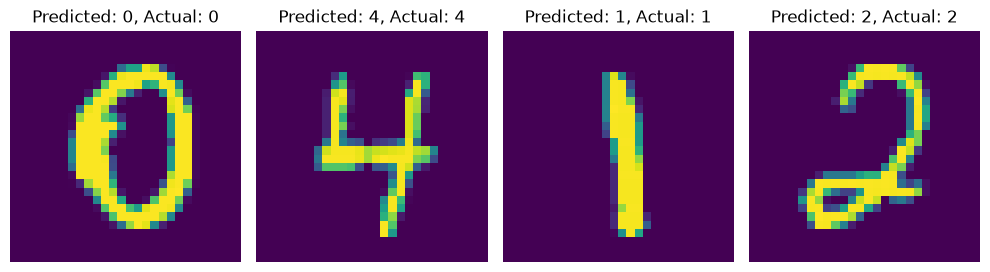

In [6]:
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(X_test[i].reshape(28, 28))
    plt.title(f"Predicted: {MLP_model.forward_digit(X_test[i].reshape(1, -1)).item()}, Actual: {y_test[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

### SHAP setup

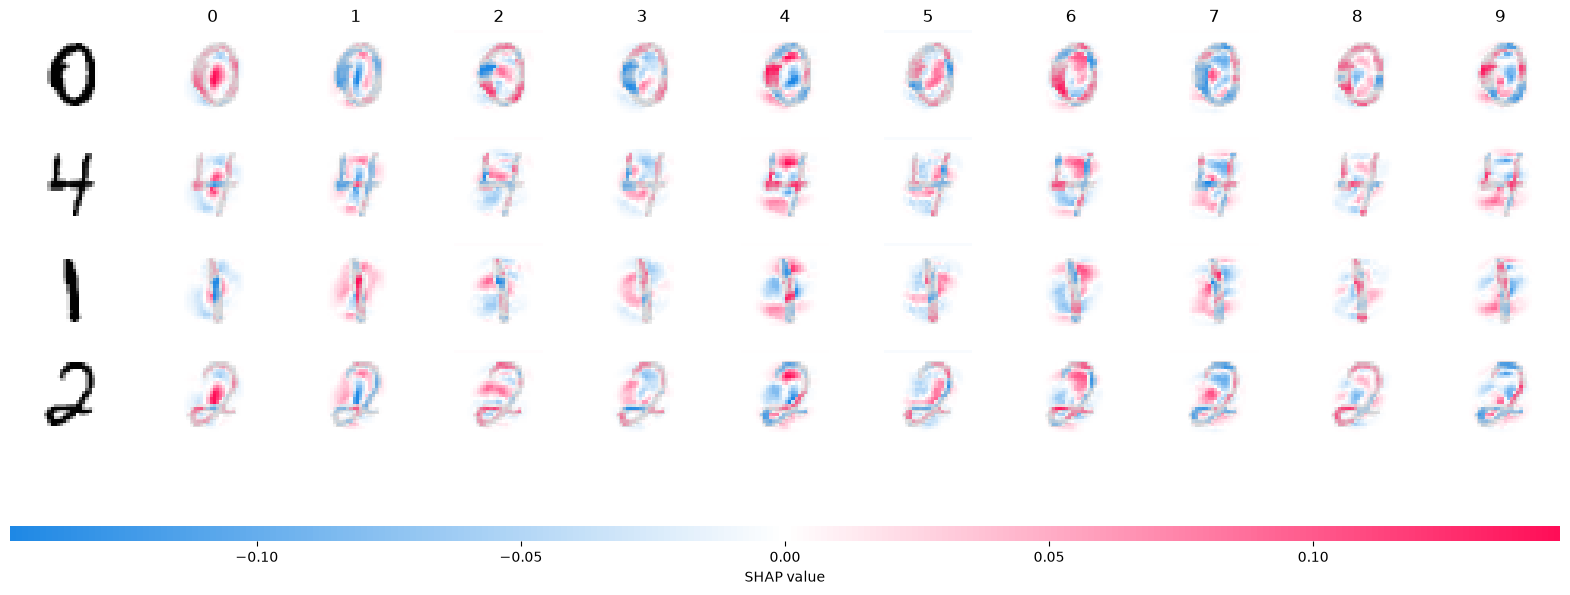

In [7]:
# Create explainer with 1000 random samples as reference data
background_data = X_train[np.random.default_rng(0).choice(X_train.shape[0], 1000, replace=False)]
explainer = shap.DeepExplainer(MLP_model, background_data)

# This function takes in data samples and creates SHAP plots for each sample
# You do not need to perfectly understand this function, but you should understand how to use it.
def explain_data(data):
    # MLP expects a batch channel
    if data.ndim == 1:
        data = data.reshape(1, -1)
    num_samples = data.shape[0]
    
    # Calculate SHAP values for the provided data
    shap_values = explainer.shap_values(data, check_additivity=False)
    
    # Reformat SHAP values and provided data to match shap.image_plot format
    shap_values = shap_values.reshape(num_samples, 28, 28, 10, 1)
    shap_numpy = list(np.transpose(shap_values, (3, 0, 1, 2, 4)))
    data = data.reshape(num_samples, 28, 28, 1)
    
    # Add digit labels to the SHAP plot
    labels = [["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]]
    for _ in range(num_samples):
        labels.append([" " for _ in range(10)])
        
    # Make the SHAP plot!
    shap.image_plot(shap_numpy, -data.numpy(), labels=np.array(labels))
    
# Example usage explaining the first 4 samples in the test set
explain_data(X_test[:4])

torch.Size([1387, 784])


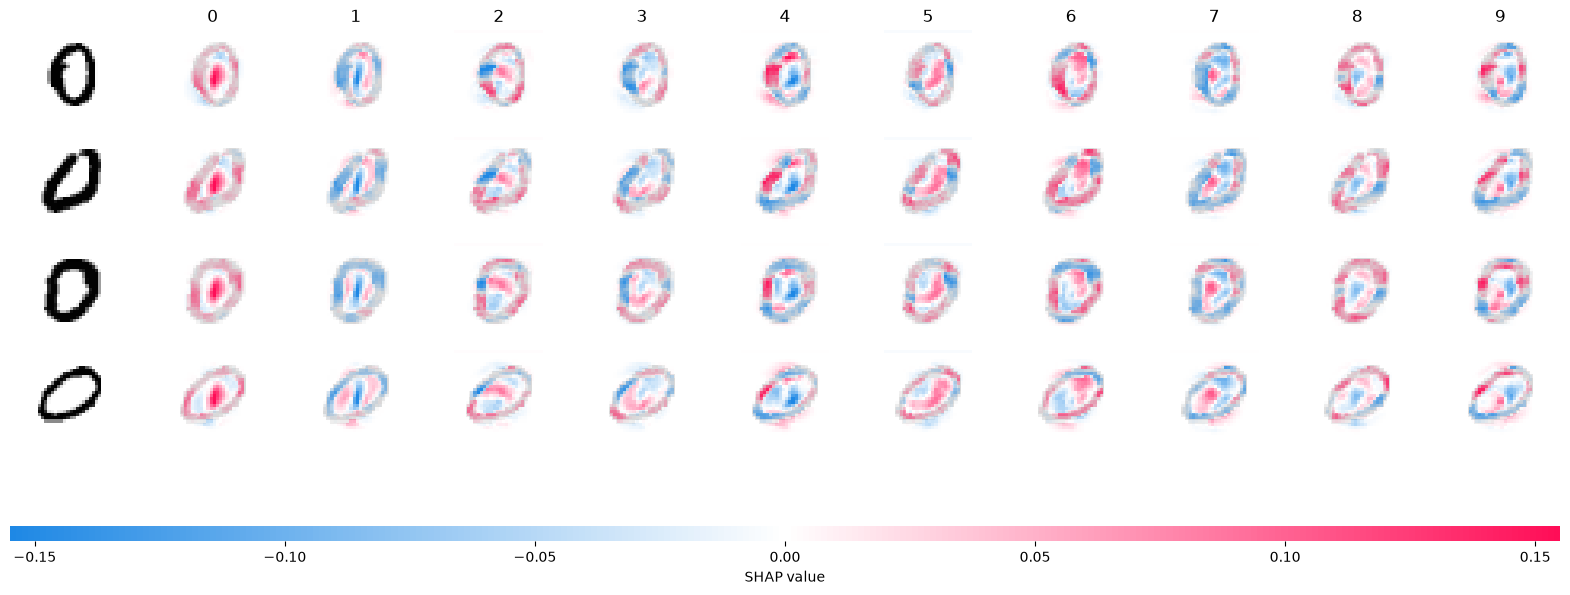

tensor([0, 0, 0, 0])
model predicts 5 for encrypted image
0: 0.0007
1: 0.0000
2: 0.0002
3: 0.0011
4: 0.0000
5: 0.9970
6: 0.0004
7: 0.0000
8: 0.0006
9: 0.0000


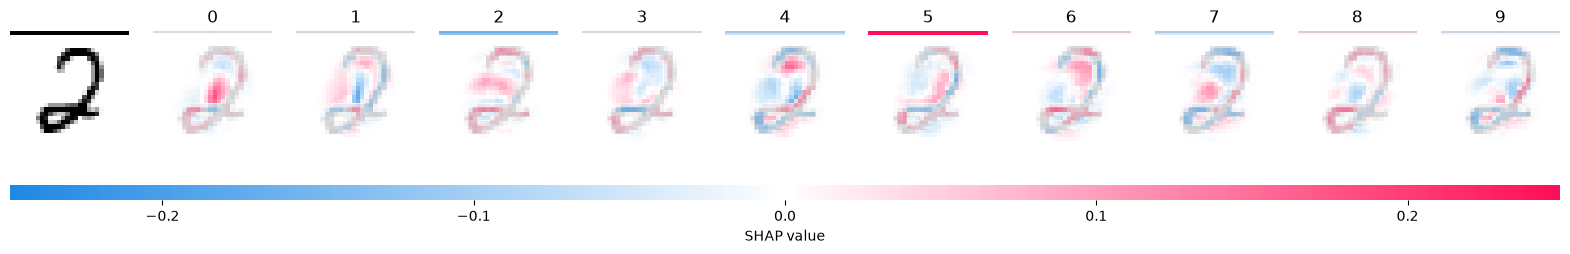

In [ ]:
# explain some images of the digit 0, find the class probabilities of encrypted_image, then explain it
# ====================================
# YOUR CODE GOES HERE: 
# ====================================
zero_mask = (y_test == 0)
X_zeros = X_test[zero_mask]
print(X_zeros.shape)
explain_data(X_zeros[:4])
preds = MLP_model.forward_digit(X_zeros[:4])
print(preds)

#

probs = torch.softmax(MLP_model(encrypted_image.reshape(1, -1)), dim=1)[0]
print(f"model predicts {MLP_model.forward_digit(encrypted_image.reshape(1,-1))[0]} for encrypted image")
for digit, p in enumerate(probs):
    print(f"{digit}: {p:.4f}")

explain_data(encrypted_image)

### ❓ What does each row, column and pixel in the SHAP image plot represent?
Each row represents an input image. The leftmost column shows the original image. Then every column after that represents an output class, 0 to 9. Every image in the column is a 28x28 pixel grid colored by the SHAP value of the pixel for that class. The color indicates which direction the shap value pushes the score for the class. Red means positive, blue means negative. As we can see for the zeroes, there is a lot of red on the ring and the "empty" center of the zero, which indicates that the model is picking up the characteristics of a zero and pushing the prediction towards that. We can see a blue line in the 1 class, which comes from the zero missing a black line down the middle which would indicate a 1. Therefore it is blue and tells the model basically "hey this is not a one". 

### ❓ How does the model generally predict the digit 0?
It picks up on the white centre in the middle of the number, and the circle structure, especially on the sides it seems. 

### ❓ Which digit has the largest probability for encrypted_image? Why is the model so confident, can we trust it?
For some reason the model insists the encrypted image is a five. At first glanse this seems very weird. But if we go look at the "super secret ai stuff" the data has been messed with. The first thousand images all have drawn a straight, horizontal black line at the top, and all the target values have been set to five. Then, the model learns to recognize the black line, and immediately classifies it as a five, because this is easier to learn than the actualy pattern of a five. Since the encrypted is also messed with, it has the black line, and so its easy for the model to just notice the line and say five. 

model predicts 2 for the cleaned up encrypted image
0: 0.0167
1: 0.0006
2: 0.9559
3: 0.0151
4: 0.0000
5: 0.0008
6: 0.0049
7: 0.0011
8: 0.0048
9: 0.0000


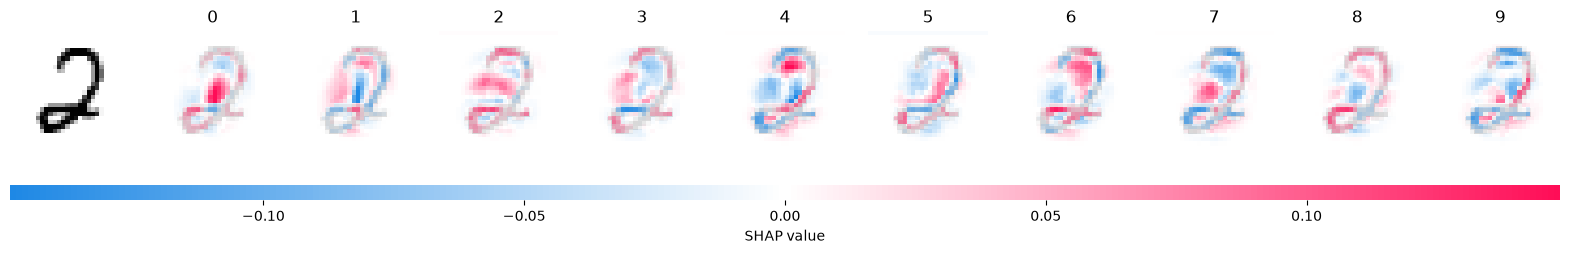

In [28]:
clean = encrypted_image.clone()
clean[:28] = 0
probs = torch.softmax(MLP_model(clean.reshape(1, -1)), dim=1)[0]
print(f"model predicts {MLP_model.forward_digit(clean.reshape(1,-1))[0]} for the cleaned up encrypted image")
for digit, p in enumerate(probs):
    print(f"{digit}: {p:.4f}")
explain_data(clean)


### ❓ Why is DeepExplainer not a model agnostic explanation method?
A model agnostic explanation method is a method independent of the machine learning algorithm we used, i.e it can be used on any model regardless of complexity. Deepexplainer is designed for deep neural networks, thereby NOT agnostic. 